# Eksperimen Tambahan - CNN untuk Data Teks

**Nama:** Agus
**NIM:** 244107020049

[Sumber modul](https://polinema.gitbook.io/jti-modul-praktikum-pembelajaran-mesin-2025-2026/js14-convolutional-neural-network)

Catatan dosen: *"Kalau di modul menggunakan dataset image, maka coba kalau CNN itu menggunakan teks gimana."*

Notebook ini mengulang **langkah yang sama** dengan Praktikum 1 dan 2, tetapi untuk teks:

| Aspek | CNN citra (modul) | CNN teks (notebook ini) |
| --- | --- | --- |
| Input | Matriks piksel H×W×3 | Urutan token → matriks *embedding* L×d |
| Konvolusi | `Conv2D` bergeser di 2 dimensi (tinggi, lebar) | `Conv1D` bergeser di 1 dimensi (posisi kata); kernel 3 = trigram |
| Pooling | `MaxPool2D` | `MaxPool1D` |
| Pra-pengolahan | Resize, rescale, augmentasi | Tokenisasi, batas kosakata, padding/truncate ke panjang tetap |
| Fitur yang dipelajari | Tepi, tekstur, bentuk | Frasa n-gram penanda kelas, misalnya "not good" |

Pendekatan ini mengikuti Kim (2014), yang menerapkan CNN satu lapis pada *word embedding* untuk klasifikasi kalimat.

* **Bagian A (analog Praktikum 1, biner):** IMDB movie review sentiment (Maas dkk., 2011), positif vs negatif. Dataset tersedia di `tensorflow.keras.datasets.imdb`.
* **Bagian B (analog Praktikum 2, 10 kelas):** 20 Newsgroups (Lang, 1995) yang dibatasi ke 10 topik agar setara dengan 10 kelas CIFAR-10.
  Header, signature, dan kutipan dihapus (`remove=...`) agar model tidak menghafal alamat email pengirim.

In [1]:
import sys
import numpy as np
import tensorflow as tf
tf.keras.utils.set_random_seed(42)
print("Kernel:", sys.executable)
print("TensorFlow:", tf.__version__)

Kernel: /Users/jergal/College/machine-learning-smt-5/.venv/bin/python
TensorFlow: 2.21.0


## Bagian A - Sentimen IMDB (mengikuti langkah Praktikum 1)

### Langkah 1 - Import Library

In [2]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.datasets import imdb
from tensorflow.keras.preprocessing.sequence import pad_sequences

### Langkah 2 - Pra Pengolahan Data

Analog dengan *resize* 64×64 pada citra, setiap ulasan dipotong atau di-*padding* ke **200 token**. Kosakata dibatasi pada
10.000 kata paling sering. IMDB sudah terbagi 25.000 data training dan 25.000 data testing.

In [3]:
VOCAB, MAXLEN = 10000, 200
(x_train_seq, y_train), (x_test_seq, y_test) = imdb.load_data(num_words=VOCAB)
lengths = [len(s) for s in x_train_seq]
print(f'train={len(x_train_seq)}, test={len(x_test_seq)}, positif={y_train.mean():.2f}')
print(f'Panjang ulasan (token): median={np.median(lengths):.0f}, persentil-90={np.percentile(lengths, 90):.0f}')

training_set = pad_sequences(x_train_seq, maxlen=MAXLEN, padding='post', truncating='post')
test_set = pad_sequences(x_test_seq, maxlen=MAXLEN, padding='post', truncating='post')

word_index = imdb.get_word_index()
index_word = {i + 3: w for w, i in word_index.items()} | {0: '<pad>', 1: '<start>', 2: '<unk>'}
print('Contoh ulasan:', ' '.join(index_word.get(i, '?') for i in x_train_seq[0][:40]), '...')
print('Label:', 'positif' if y_train[0] else 'negatif')

train=25000, test=25000, positif=0.50
Panjang ulasan (token): median=178, persentil-90=467


      0/1641221 ━━━━━━━━━━━━━━━━━━━━ 0s 0s/step

  24576/1641221 ━━━━━━━━━━━━━━━━━━━━ 3s 2us/step

  81920/1641221 ━━━━━━━━━━━━━━━━━━━━ 1s 1us/step

 180224/1641221 ━━━━━━━━━━━━━━━━━━━━ 1s 1us/step

 352256/1641221 ━━━━━━━━━━━━━━━━━━━━ 0s 1us/step

 794624/1641221 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step

1597440/1641221 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step

1641221/1641221 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Contoh ulasan: <start> this film was just brilliant casting location scenery story direction everyone's really suited the part they played and you could just imagine being there robert <unk> is an amazing actor and now the same being director <unk> father came ...
Label: positif


### Langkah 3 - Pembuatan Model CNN Teks (layer demi layer seperti modul)

In [4]:
tf.keras.utils.set_random_seed(42)
cnn = tf.keras.models.Sequential()
# 3.1 Input + embedding: setiap token menjadi vektor 64 dimensi (pengganti kanal RGB)
cnn.add(tf.keras.layers.Input(shape=(MAXLEN,)))
cnn.add(tf.keras.layers.Embedding(input_dim=VOCAB, output_dim=64))
# 3.2 Konvolusi 1
cnn.add(tf.keras.layers.Conv1D(filters=32, kernel_size=3, activation='relu'))
# 3.3 Pooling 1
cnn.add(tf.keras.layers.MaxPool1D(pool_size=2, strides=2))
# 3.4 Konvolusi 2 dan Pooling 2
cnn.add(tf.keras.layers.Conv1D(filters=32, kernel_size=3, activation='relu'))
cnn.add(tf.keras.layers.MaxPool1D(pool_size=2, strides=2))
# 3.5 Flattening
cnn.add(tf.keras.layers.Flatten())
# 3.6 Fully connected 1
cnn.add(tf.keras.layers.Dense(units=128, activation='relu'))
# 3.7 Output
cnn.add(tf.keras.layers.Dense(units=1, activation='sigmoid'))
# 3.8 Compile
cnn.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
cnn.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 200, 64)        │       640,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d (Conv1D)                 │ (None, 198, 32)        │         6,176 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 99, 32)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 97, 32)         │         3,104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_1 (MaxPooling1D)  │ (None, 48, 32)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1536)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       196,736 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 846,145 (3.23 MB)

 Trainable params: 846,145 (3.23 MB)

 Non-trainable params: 0 (0.00 B)

### Langkah 4 - Fit CNN (25 epoch, data test sebagai validasi seperti modul)

Epoch 1/25


782/782 - 3s - 4ms/step - accuracy: 0.7853 - loss: 0.4192 - val_accuracy: 0.8636 - val_loss: 0.3176


Epoch 2/25


782/782 - 3s - 3ms/step - accuracy: 0.9175 - loss: 0.2093 - val_accuracy: 0.8565 - val_loss: 0.3633


Epoch 3/25


782/782 - 3s - 3ms/step - accuracy: 0.9568 - loss: 0.1188 - val_accuracy: 0.8401 - val_loss: 0.4969


... (41 outputs left out)

782/782 - 3s - 4ms/step - accuracy: 0.9974 - loss: 0.0075 - val_accuracy: 0.8327 - val_loss: 1.6590


Epoch 25/25


782/782 - 3s - 4ms/step - accuracy: 0.9995 - loss: 0.0016 - val_accuracy: 0.8384 - val_loss: 1.7321


Waktu latih: 75.4 detik


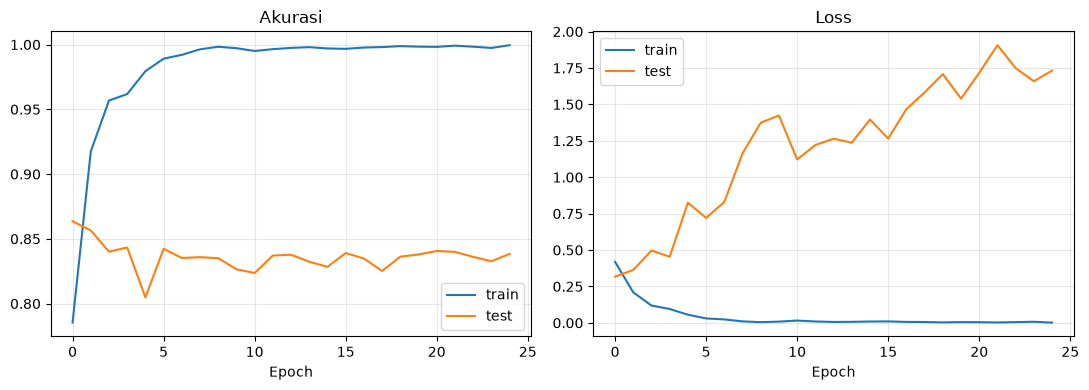

In [5]:
t0 = time.perf_counter()
history = cnn.fit(x=training_set, y=y_train, validation_data=(test_set, y_test), epochs=25, batch_size=32, verbose=2)
print(f'Waktu latih: {time.perf_counter() - t0:.1f} detik')
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(history.history['accuracy'], label='train'); ax[0].plot(history.history['val_accuracy'], label='test')
ax[1].plot(history.history['loss'], label='train'); ax[1].plot(history.history['val_loss'], label='test')
ax[0].set_title('Akurasi'); ax[1].set_title('Loss')
for a in ax: a.set_xlabel('Epoch'); a.legend(); a.grid(alpha=.3)
plt.tight_layout(); plt.show()

Grafik di atas menunjukkan overfitting: akurasi train mendekati 100% sementara loss test terus naik. Untuk perbandingan yang adil,
model yang sama dilatih ulang dengan EarlyStopping. Data validasinya diambil 20% dari data **train**, bukan data test.

In [6]:
def build_text_cnn():
    tf.keras.utils.set_random_seed(42)
    m = tf.keras.models.clone_model(cnn)
    m.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
    return m

cnn_es = build_text_cnn()
es = tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=2, restore_best_weights=True)
t0 = time.perf_counter()
h_es = cnn_es.fit(training_set, y_train, validation_split=0.2, epochs=25, batch_size=32, callbacks=[es], verbose=0)
cnn_time = time.perf_counter() - t0
_, acc_25 = cnn.evaluate(test_set, y_test, verbose=0)
_, acc_es = cnn_es.evaluate(test_set, y_test, verbose=0)
print(f'Akurasi test - 25 epoch: {acc_25:.4f} | EarlyStopping ({len(h_es.history["loss"])} epoch): {acc_es:.4f}')

Akurasi test - 25 epoch: 0.8384 | EarlyStopping (3 epoch): 0.8600


### Langkah 5 - Prediksi dengan 1 Teks

In [7]:
import re

def encode(text):
    tokens = re.findall(r"[a-z0-9']+", text.lower())
    ids = [1] + [(word_index[t] + 3) if t in word_index and word_index[t] + 3 < VOCAB else 2 for t in tokens]
    return pad_sequences([ids], maxlen=MAXLEN, padding='post', truncating='post')

reviews = ['This movie was absolutely wonderful, the acting was brilliant and the story kept me hooked until the end.',
           'A boring and predictable film. The plot made no sense and I wasted two hours of my life.',
           'Not bad at all, but the ending was disappointing.']
for text in reviews:
    result = cnn_es.predict(encode(text), verbose=0)
    prediction = 'positif' if result[0][0] > 0.5 else 'negatif'
    print(f'{prediction:8s} (p={result[0][0]:.3f})  {text}')

positif  (p=0.972)  This movie was absolutely wonderful, the acting was brilliant and the story kept me hooked until the end.
negatif  (p=0.072)  A boring and predictable film. The plot made no sense and I wasted two hours of my life.
negatif  (p=0.122)  Not bad at all, but the ending was disappointing.


### Perbandingan CNN teks dengan baseline

Baseline klasik klasifikasi teks adalah *bag-of-n-grams* TF-IDF + model linier (Joachims, 1998; Wang & Manning, 2012).
Baseline dilatih pada token dan kosakata yang sama (10.000 kata, tanpa pemotongan 200 token) dengan unigram dan bigram.

In [8]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score

as_text = lambda seqs: [' '.join(map(str, s)) for s in seqs]
t0 = time.perf_counter()
tfidf = TfidfVectorizer(token_pattern=r'\d+', ngram_range=(1, 2), min_df=2, sublinear_tf=True)
Xtr_tfidf = tfidf.fit_transform(as_text(x_train_seq)); Xte_tfidf = tfidf.transform(as_text(x_test_seq))
logreg = LogisticRegression(C=4, max_iter=2000).fit(Xtr_tfidf, y_train)
lr_time = time.perf_counter() - t0
p_lr = logreg.predict(Xte_tfidf)
p_cnn = (cnn_es.predict(test_set, verbose=0).ravel() > 0.5).astype(int)
p_cnn25 = (cnn.predict(test_set, verbose=0).ravel() > 0.5).astype(int)
imdb_table = pd.DataFrame([
    {'model': 'TF-IDF uni+bigram + Logistic Regression', 'test_acc': accuracy_score(y_test, p_lr), 'F1': f1_score(y_test, p_lr), 'waktu_latih_s': lr_time},
    {'model': 'CNN teks, 25 epoch (langkah modul)', 'test_acc': accuracy_score(y_test, p_cnn25), 'F1': f1_score(y_test, p_cnn25), 'waktu_latih_s': np.nan},
    {'model': 'CNN teks + EarlyStopping', 'test_acc': accuracy_score(y_test, p_cnn), 'F1': f1_score(y_test, p_cnn), 'waktu_latih_s': cnn_time},
]).set_index('model')
imdb_table.round(4)

,test_acc,F1,waktu_latih_s
model,,,
TF-IDF uni+bigram + Logistic Regression,0.9080,0.9083,8.0108
"CNN teks, 25 epoch (langkah modul)",0.8384,0.8343,NaN
CNN teks + EarlyStopping,0.8600,0.8586,6.3291


## Bagian B - 20 Newsgroups 10 topik (mengikuti langkah Praktikum 2)

### Langkah 1-2 - Load library dan dataset

In [9]:
from sklearn.datasets import fetch_20newsgroups
CATEGORIES = ['comp.graphics', 'misc.forsale', 'rec.autos', 'rec.sport.hockey', 'sci.crypt', 'sci.med', 'sci.space', 'soc.religion.christian', 'talk.politics.guns', 'talk.politics.mideast']
train_raw = fetch_20newsgroups(subset='train', categories=CATEGORIES, remove=('headers', 'footers', 'quotes'), random_state=42)
test_raw = fetch_20newsgroups(subset='test', categories=CATEGORIES, remove=('headers', 'footers', 'quotes'), random_state=42)
class_names = train_raw.target_names
train_labels, test_labels = train_raw.target, test_raw.target
print(len(train_raw.data), 'train |', len(test_raw.data), 'test')

# "Normalisasi" teks: tokenisasi + batasi kosakata + panjang tetap (setara pembagian /255 pada citra)
MAX_TOKENS, SEQ_LEN = 20000, 300
vectorizer = tf.keras.layers.TextVectorization(max_tokens=MAX_TOKENS, output_sequence_length=SEQ_LEN)
vectorizer.adapt(train_raw.data)
train_texts = vectorizer(np.array(train_raw.data)).numpy()
test_texts = vectorizer(np.array(test_raw.data)).numpy()
print(train_texts.shape, test_texts.shape)

5854 train | 3898 test


(5854, 300) (3898, 300)


### Langkah 3 - Verifikasi Data

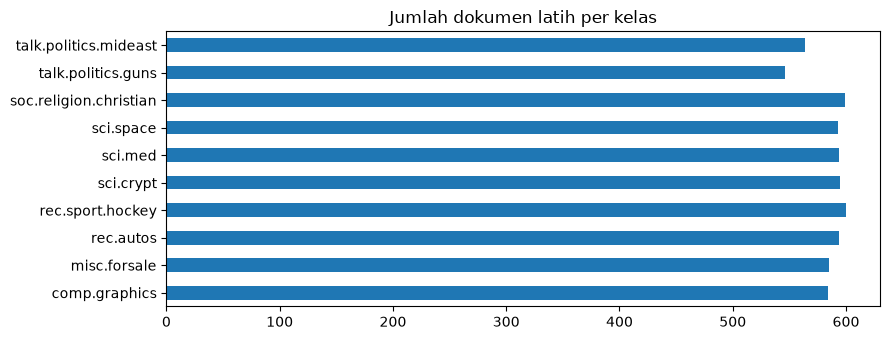

,kelas,cuplikan teks
0,sci.crypt,"No, he gives the keys to the FBI (who may then..."
1,comp.graphics,To everyone who wants fonts in Vivid/POV/Polyr...
2,comp.graphics,": >Hi Netters, : > : >I'm building a CAD packa..."
3,misc.forsale,"Hi netters, Does anyone know have any info on ..."
4,comp.graphics,Hi ! If you want to have Soft-Scrolling on you...
5,rec.autos,There was a Volvo owner that had $3000 dollars...
6,sci.space,I note that you make no such case as you claim...
7,rec.sport.hockey,It was great to hear that UMass is bringing ba...


In [10]:
fig, ax = plt.subplots(figsize=(9, 3.5))
pd.Series(train_labels).map(dict(enumerate(class_names))).value_counts().sort_index().plot.barh(ax=ax)
ax.set_title('Jumlah dokumen latih per kelas'); plt.tight_layout(); plt.show()
pd.DataFrame({'kelas': [class_names[l] for l in train_labels[:8]],
              'cuplikan teks': [' '.join(t.split())[:110] for t in train_raw.data[:8]]})

### Langkah 4 - Buat Model CNN (pola konvolusi sama dengan Praktikum 2, Conv2D → Conv1D)

In [11]:
from tensorflow.keras import layers, models
tf.keras.utils.set_random_seed(42)
model = models.Sequential()
model.add(layers.Input(shape=(SEQ_LEN,)))
model.add(layers.Embedding(MAX_TOKENS, 64))
model.add(layers.Conv1D(32, 3, activation='relu'))
model.add(layers.MaxPooling1D(2))
model.add(layers.Conv1D(64, 3, activation='relu'))
model.add(layers.MaxPooling1D(2))
model.add(layers.Conv1D(64, 3, activation='relu'))
model.add(layers.Flatten())
model.add(layers.Dense(64, activation='relu'))
model.add(layers.Dense(10))
model.summary()
model.compile(optimizer='adam', loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True), metrics=['accuracy'])

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ (None, 300, 64)        │     1,280,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_2 (Conv1D)               │ (None, 298, 32)        │         6,176 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_2 (MaxPooling1D)  │ (None, 149, 32)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_3 (Conv1D)               │ (None, 147, 64)        │         6,208 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_3 (MaxPooling1D)  │ (None, 73, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_4 (Conv1D)               │ (None, 71, 64)         │        12,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 4544)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │       290,880 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,596,266 (6.09 MB)

 Trainable params: 1,596,266 (6.09 MB)

 Non-trainable params: 0 (0.00 B)

### Langkah 5-7 - Fit, evaluasi, cetak akurasi

Epoch 1/10


183/183 - 1s - 8ms/step - accuracy: 0.1831 - loss: 2.1126 - val_accuracy: 0.1963 - val_loss: 2.0478


Epoch 2/10


183/183 - 1s - 7ms/step - accuracy: 0.3423 - loss: 1.5960 - val_accuracy: 0.3286 - val_loss: 1.7988


Epoch 3/10


183/183 - 1s - 6ms/step - accuracy: 0.4974 - loss: 1.2472 - val_accuracy: 0.3961 - val_loss: 1.7919


... (10 outputs left out)

Epoch 9/10


183/183 - 1s - 6ms/step - accuracy: 0.9303 - loss: 0.2101 - val_accuracy: 0.5749 - val_loss: 2.2069


Epoch 10/10


183/183 - 1s - 6ms/step - accuracy: 0.9486 - loss: 0.1590 - val_accuracy: 0.5654 - val_loss: 2.6240


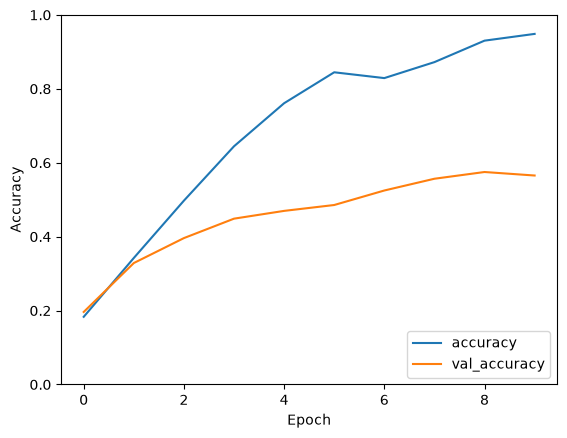

122/122 - 0s - 1ms/step - accuracy: 0.5654 - loss: 2.6240


0.5654181838035583


In [12]:
history = model.fit(train_texts, train_labels, epochs=10, validation_data=(test_texts, test_labels), verbose=2)
plt.plot(history.history['accuracy'], label='accuracy')
plt.plot(history.history['val_accuracy'], label='val_accuracy')
plt.xlabel('Epoch'); plt.ylabel('Accuracy'); plt.ylim([0.0, 1]); plt.legend(loc='lower right'); plt.show()
test_loss, test_acc = model.evaluate(test_texts, test_labels, verbose=2)
print(test_acc)

`ylim` diperlebar ke 0-1 (modul: 0,5-1) karena akurasi awal pada teks berada di bawah 0,5.

### Modifikasi: CNN gaya Kim (2014)

Arsitektur Kim (2014) memakai beberapa ukuran kernel paralel (3, 4, 5), *global max pooling* untuk mengambil satu fitur terkuat per filter,
dan dropout 0,5. Bentuk ini lebih cocok untuk teks daripada `Flatten` dari pola CIFAR karena posisi absolut kata dalam dokumen
tidak penting. Zhang & Wallace (2017) juga menunjukkan bahwa *1-max pooling* konsisten lebih baik daripada strategi pooling lain.

In [13]:
tf.keras.utils.set_random_seed(42)
inp = layers.Input(shape=(SEQ_LEN,))
emb = layers.Dropout(0.2)(layers.Embedding(MAX_TOKENS, 128)(inp))
branches = [layers.GlobalMaxPooling1D()(layers.Conv1D(128, k, activation='relu')(emb)) for k in (3, 4, 5)]
x = layers.Dropout(0.5)(layers.Concatenate()(branches))
kim = models.Model(inp, layers.Dense(10)(x))
kim.compile(optimizer='adam', loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True), metrics=['accuracy'])
es = tf.keras.callbacks.EarlyStopping(monitor='val_accuracy', patience=3, restore_best_weights=True)
kh = kim.fit(train_texts, train_labels, validation_split=0.15, epochs=30, batch_size=32, callbacks=[es], verbose=0)
_, kim_acc = kim.evaluate(test_texts, test_labels, verbose=0)
print(f'Kim-CNN: {len(kh.history["loss"])} epoch, akurasi test {kim_acc:.4f}')

Kim-CNN: 13 epoch, akurasi test 0.7912


,test_acc,macro_F1
model,,
TF-IDF uni+bigram + Linear SVM,0.8327,0.8332
CNN pola Praktikum 2 (Conv1D + Flatten),0.5654,0.5625
Kim-CNN (kernel 3/4/5 + global max pool),0.7912,0.7925


                        precision    recall  f1-score   support

         comp.graphics      0.800     0.812     0.806       389
          misc.forsale      0.848     0.872     0.860       390
             rec.autos      0.602     0.828     0.697       396
      rec.sport.hockey      0.882     0.897     0.889       399
             sci.crypt      0.865     0.727     0.790       396
               sci.med      0.738     0.725     0.731       396
             sci.space      0.792     0.723     0.756       394
soc.religion.christian      0.855     0.827     0.840       398
    talk.politics.guns      0.733     0.723     0.728       364
 talk.politics.mideast      0.892     0.771     0.827       376

              accuracy                          0.791      3898
             macro avg      0.801     0.791     0.792      3898
          weighted avg      0.801     0.791     0.793      3898



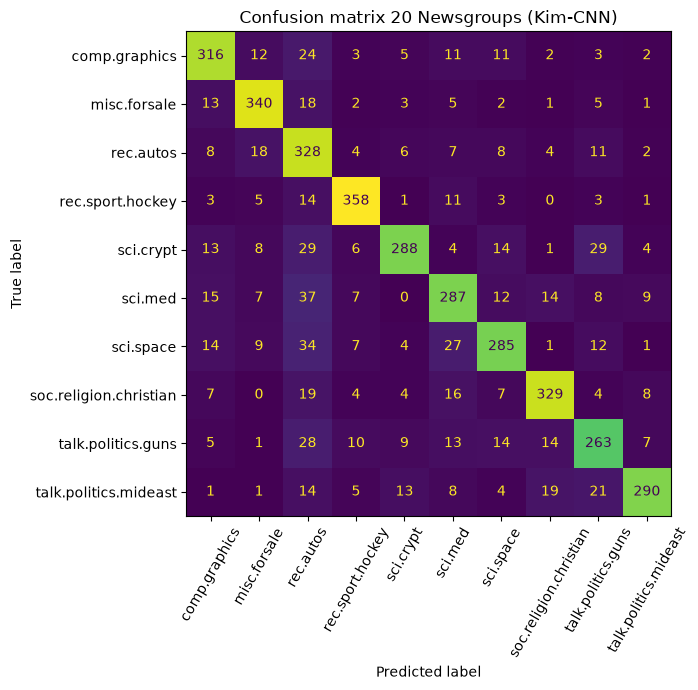

In [14]:
from sklearn.svm import LinearSVC
from sklearn.metrics import classification_report, ConfusionMatrixDisplay
tfidf20 = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True, max_features=200000)
Xtr20 = tfidf20.fit_transform(train_raw.data); Xte20 = tfidf20.transform(test_raw.data)
p_svm = LinearSVC(C=0.5).fit(Xtr20, train_labels).predict(Xte20)
p_kim = kim.predict(test_texts, verbose=0).argmax(1)
p_base = model.predict(test_texts, verbose=0).argmax(1)
ng_table = pd.DataFrame([
    {'model': 'TF-IDF uni+bigram + Linear SVM', 'test_acc': accuracy_score(test_labels, p_svm), 'macro_F1': f1_score(test_labels, p_svm, average='macro')},
    {'model': 'CNN pola Praktikum 2 (Conv1D + Flatten)', 'test_acc': accuracy_score(test_labels, p_base), 'macro_F1': f1_score(test_labels, p_base, average='macro')},
    {'model': 'Kim-CNN (kernel 3/4/5 + global max pool)', 'test_acc': accuracy_score(test_labels, p_kim), 'macro_F1': f1_score(test_labels, p_kim, average='macro')},
]).set_index('model')
display(ng_table.round(4))
print(classification_report(test_labels, p_kim, target_names=class_names, digits=3))
fig, ax = plt.subplots(figsize=(8, 7))
ConfusionMatrixDisplay.from_predictions(test_labels, p_kim, display_labels=class_names, ax=ax, colorbar=False, xticks_rotation=60)
plt.title('Confusion matrix 20 Newsgroups (Kim-CNN)'); plt.tight_layout(); plt.show()

## Analisis dan perbandingan dengan literatur

### Bagian A - IMDB (biner)

| Model | Akurasi test | F1 | Waktu latih |
| --- | --- | --- | --- |
| CNN teks, 25 epoch (langkah modul) | 83,84% | 0,834 | 75 s |
| CNN teks + EarlyStopping (3 epoch) | 86,00% | 0,859 | 6 s |
| **TF-IDF uni+bigram + Logistic Regression** | **90,80%** | **0,908** | 8 s |

* **CNN dapat dipakai untuk teks.** Dengan langkah yang sama seperti CNN cat-dog (Conv → Pool → Conv → Pool → Flatten → Dense), dan hanya mengganti `Conv2D` dengan `Embedding` + `Conv1D`, model mencapai 86%. Prediksi ulasan baru juga masuk akal: ulasan pujian diberi p = 0,97 dan ulasan kritik p = 0,07. Kernel berukuran 3 bekerja seperti detektor trigram, misalnya frasa "absolutely wonderful" atau "wasted two hours".
* **Overfitting jauh lebih cepat daripada pada citra.** Akurasi train sudah 95,7% pada epoch 3 dan di atas 99% sejak epoch 7. Akurasi test tertinggi justru tercapai pada epoch 1 (86,4%) dan berakhir di 83,8% pada epoch 25. Pada citra, augmentasi menahan overfitting. Teks tidak memiliki augmentasi sederhana yang setara dengan flip/zoom, dan *embedding* 10.000 × 64 (640 ribu parameter) mudah menghafal 25.000 ulasan. Kim (2014) karena itu memakai dropout 0,5 dan *embedding* pra-latih.
* **Keterbatasan.** Ulasan "Not bad at all, but the ending was disappointing" diprediksi negatif (p = 0,12). Kalimat ini ambigu, dan negasi "not bad" sulit ditangkap karena kata "bad" dan "disappointing" sangat kuat menandai ulasan negatif.
* **Baseline linier lebih unggul.** TF-IDF n-gram + regresi logistik mencapai 90,8%, 4,8 poin di atas CNN, dengan waktu latih yang setara. Hasil ini sejalan dengan literatur: Maas dkk. (2011) melaporkan 88,89% pada IMDB, Wang & Manning (2012) mencapai 91,2% dengan NBSVM bigram, dan CNN baru melampaui baseline n-gram ketika arsitekturnya disesuaikan untuk dokumen panjang (Johnson & Zhang, 2015). Zhang dkk. (2015) juga menemukan bahwa TF-IDF n-gram tetap lebih baik daripada CNN pada dataset hingga ratusan ribu sampel. CNN baru unggul pada skala jutaan dokumen.

### Bagian B - 20 Newsgroups 10 topik

| Model | Akurasi test | Macro F1 |
| --- | --- | --- |
| CNN pola Praktikum 2 (Conv1D + Flatten) | 56,54% | 0,563 |
| Kim-CNN (kernel 3/4/5 + global max pool + dropout) | 79,12% | 0,793 |
| **TF-IDF uni+bigram + Linear SVM** | **83,27%** | **0,833** |

* **Menyalin pola CIFAR apa adanya tidak cocok untuk teks** (56,5%). `Flatten` menghubungkan setiap posisi token ke neuron Dense secara terpisah, sehingga model mempelajari "kata X di posisi 120". Pada citra, posisi relatif piksel bermakna. Pada dokumen sepanjang 300 token, topik ditentukan oleh **keberadaan** frasa, bukan posisinya. Akibatnya, dengan 5.854 dokumen latih, model menghafal: akurasi train mencapai 94,9%, sedangkan akurasi test hanya 56,5%.
* **Arsitektur khusus teks naik 22,6 poin.** *Global max pooling* mengambil satu nilai terkuat per filter dari seluruh dokumen, sehingga model tidak bergantung pada posisi. Kernel paralel 3/4/5 menangkap n-gram dengan panjang berbeda. Kim (2014) memakai kombinasi ini, dan Zhang & Wallace (2017) menunjukkan bahwa *1-max pooling* konsisten lebih baik daripada strategi pooling lain pada klasifikasi kalimat.
* **SVM linier tetap terbaik.** Sejak Joachims (1998), SVM pada fitur TF-IDF berdimensi tinggi dikenal kuat untuk kategorisasi teks, karena fitur teks *sparse* dan sebagian besar kelasnya terpisah secara linier. Kelas tersulit untuk Kim-CNN adalah `rec.autos` (precision 0,60), karena banyak dokumen kelas lain ikut diprediksi sebagai rec.autos (recall 0,83 tetapi precision rendah), dan `talk.politics.guns` (F1 0,73).

### Kesimpulan CNN citra vs CNN teks

| Aspek | CNN citra (Praktikum 1-2) | CNN teks (eksperimen ini) |
| --- | --- | --- |
| Kecocokan inductive bias | Tinggi: lokalitas spasial dan invariansi translasi sesuai sifat citra | Sedang: lokalitas n-gram cocok, tetapi posisi absolut tidak penting, sehingga butuh global pooling |
| Baseline klasik | Fitur manual (HOG, histogram) jauh di bawah CNN pada data besar | TF-IDF + model linier sangat kuat dan mengungguli CNN pada data ini |
| Overfitting | Ditekan dengan augmentasi | Lebih cepat; augmentasi teks tidak sederhana, butuh dropout atau *embedding* pra-latih |

CNN dapat diterapkan pada teks dan bekerja wajar, tetapi untuk dataset berukuran puluhan ribu dokumen, model linier berbasis n-gram masih menjadi baseline yang harus dikalahkan terlebih dahulu.

## Rujukan

1. Kim, Y. (2014). Convolutional neural networks for sentence classification. *Proceedings of the 2014 Conference on Empirical Methods in Natural Language Processing (EMNLP)*, 1746-1751. https://doi.org/10.3115/v1/D14-1181
2. Zhang, Y., & Wallace, B. C. (2017). A sensitivity analysis of (and practitioners' guide to) convolutional neural networks for sentence classification. *Proceedings of the 8th International Joint Conference on Natural Language Processing (IJCNLP)*, 253-263.
3. Zhang, X., Zhao, J., & LeCun, Y. (2015). Character-level convolutional networks for text classification. *Advances in Neural Information Processing Systems 28 (NeurIPS)*, 649-657.
4. Maas, A. L., Daly, R. E., Pham, P. T., Huang, D., Ng, A. Y., & Potts, C. (2011). Learning word vectors for sentiment analysis. *Proceedings of the 49th Annual Meeting of the ACL*, 142-150.
5. Wang, S., & Manning, C. D. (2012). Baselines and bigrams: Simple, good sentiment and topic classification. *Proceedings of the 50th Annual Meeting of the ACL (Volume 2)*, 90-94.
6. Joachims, T. (1998). Text categorization with support vector machines: Learning with many relevant features. *European Conference on Machine Learning (ECML)*, LNCS 1398, 137-142. https://doi.org/10.1007/BFb0026683
7. Lang, K. (1995). NewsWeeder: Learning to filter netnews. *Proceedings of the 12th International Conference on Machine Learning (ICML)*, 331-339.
8. Johnson, R., & Zhang, T. (2015). Effective use of word order for text categorization with convolutional neural networks. *Proceedings of NAACL-HLT 2015*, 103-112. https://doi.org/10.3115/v1/N15-1011